# Descriptive Analytics

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data_charge = pd.read_pickle("data_charge_prep.pkl")

In [3]:
print(f"Samples for site 1: {len(data_charge[data_charge['siteID']==1])}")
print(f"Samples for site 2: {len(data_charge[data_charge['siteID']==2])}")

Samples for site 1: 33599
Samples for site 2: 31192


# Note: We have 10% more samples for site 1, than for site 2. Our model might be better to predict the values for site 1.

### Temporal Patterns and Seasonality
 Demonstrate how the number of charging events varies during
 the day, the week, and between seasons. What patterns can you observe, and how do you explain
 them?

#### Pattern during the day

Discuss: eventuell nicht nur auf connectionTime sondern gesamten Ladezyklus?

In [4]:
# data_charge[data_charge["siteID"]==2]

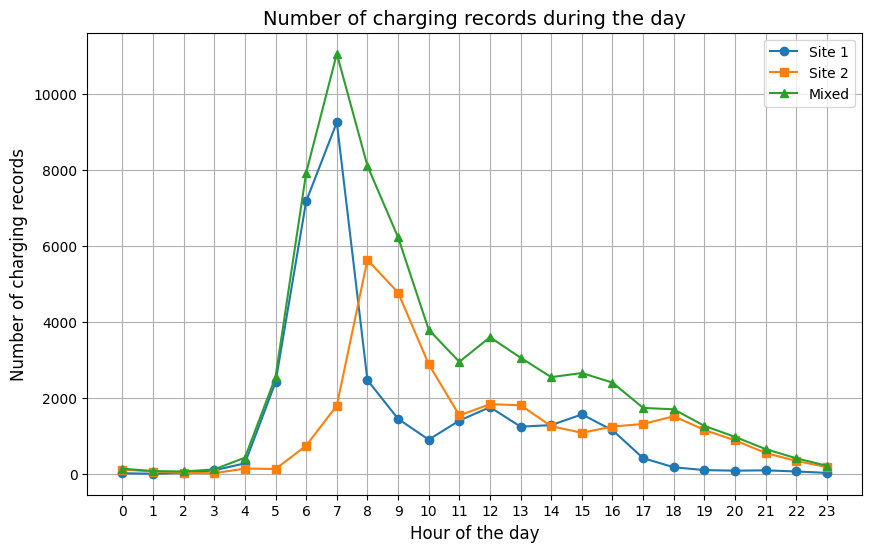

In [4]:
data_charge["hour"] = data_charge["connectionTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [6]:
# # Backup
# charging_by_hour = data_charge["hour"].value_counts().sort_index()
# charging_by_hour_2 = charging_by_hour+2000

# # Plot
# plt.figure(figsize=(10, 6))
# plt.plot(charging_by_hour.index, charging_by_hour.values, charging_by_hour_2.values, marker="o")
# plt.title("Number of charging records during the day", fontsize=14)
# plt.xlabel("Hour of the day", fontsize=12)
# plt.ylabel("Number of charging records", fontsize=12)
# plt.grid(True)
# plt.xticks(range(0, 24))
# plt.show()

In [5]:
data_charge.columns

Index(['Unnamed: 0', 'id', 'connectionTime', 'disconnectTime',
       'doneChargingTime', 'kWhDelivered', 'sessionID', 'siteID', 'spaceID',
       'stationID', 'timezone', 'userID', 'userInputs', 'endChargingTime',
       'chargingDurationMin', 'blockingDurationMin', 'hour'],
      dtype='object')

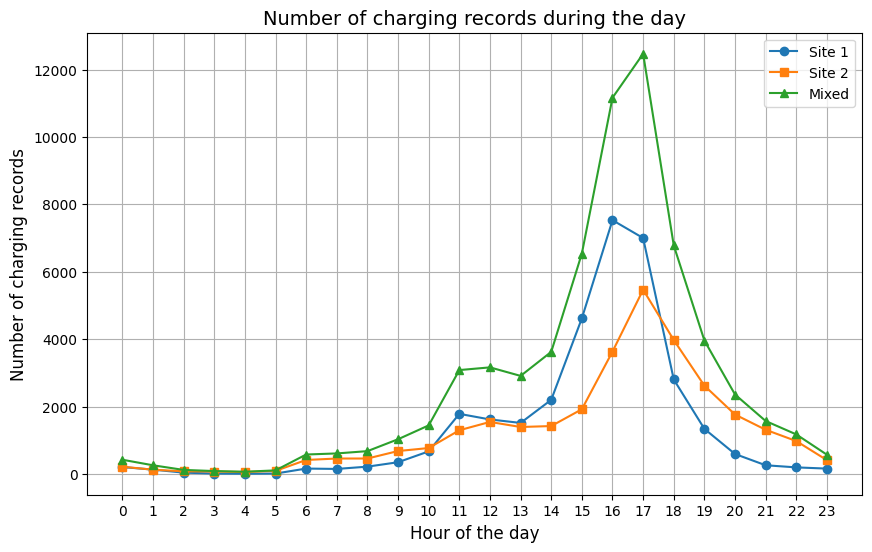

In [6]:
# Disconnect Count
data_charge["hour"] = data_charge["disconnectTime"].dt.hour
charging_by_hour_one = data_charge[data_charge["siteID"] == 1]["hour"].value_counts().sort_index()
charging_by_hour_two = data_charge[data_charge["siteID"] == 2]["hour"].value_counts().sort_index()
charging_by_hour_mixed = data_charge["hour"].value_counts().sort_index()

hours_list = [i for i in range(0, 24)]

plt.figure(figsize=(10, 6))
plt.plot(hours_list, charging_by_hour_one, label="Site 1", marker="o")
plt.plot(hours_list, charging_by_hour_two, label="Site 2", marker="s")
plt.plot(hours_list, charging_by_hour_mixed, label="Mixed", marker="^")

plt.title("Number of charging records during the day", fontsize=14)
plt.xlabel("Hour of the day", fontsize=12)
plt.xticks(range(0, 24))
plt.ylabel("Number of charging records", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

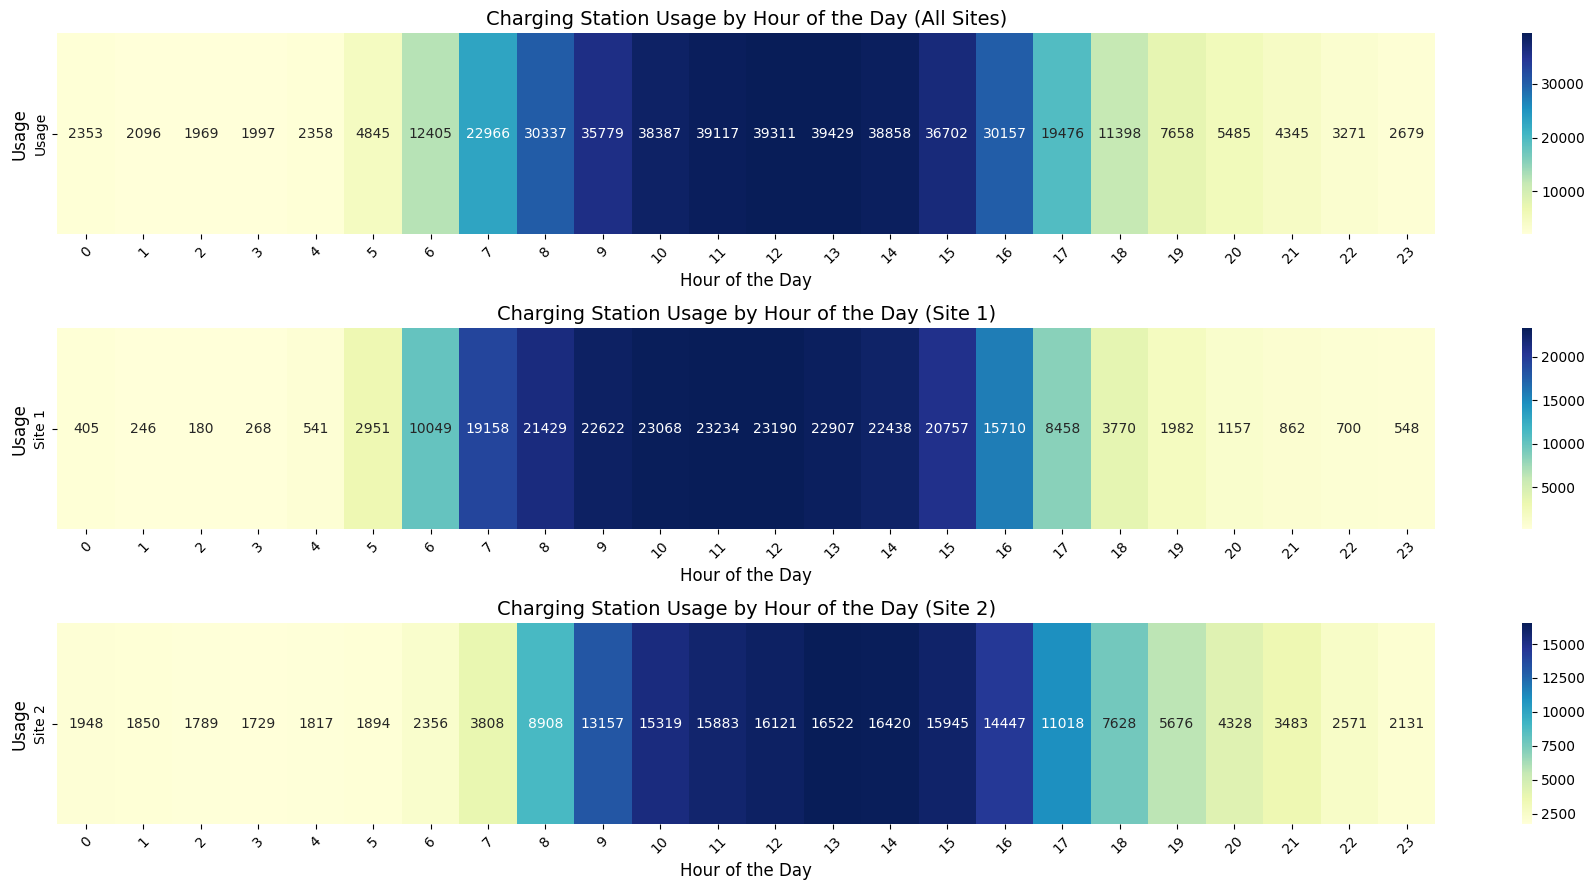

In [13]:

import seaborn as sns


data_charge["connectionTime"] = pd.to_datetime(data_charge["connectionTime"])
data_charge["disconnectTime"] = pd.to_datetime(data_charge["disconnectTime"])

def get_active_hours(row):
    active_hours = pd.date_range(row['connectionTime'], row['disconnectTime'], freq='H').hour
    return active_hours

data_charge['active_hours'] = data_charge.apply(get_active_hours, axis=1)

active_hours_flat = [hour for hours in data_charge['active_hours'] for hour in hours]

df_active_hours = pd.DataFrame(active_hours_flat, columns=['Hour'])
df_active_hours['Count'] = 1

usage_by_hour = df_active_hours.groupby('Hour').size()

data_charge_site_1 = data_charge[data_charge['siteID'] == 1]
data_charge_site_2 = data_charge[data_charge['siteID'] == 2]

active_hours_site_1 = [hour for hours in data_charge_site_1['active_hours'] for hour in hours]
active_hours_site_2 = [hour for hours in data_charge_site_2['active_hours'] for hour in hours]

df_active_hours_site_1 = pd.DataFrame(active_hours_site_1, columns=['Hour'])
df_active_hours_site_1['Count'] = 1

df_active_hours_site_2 = pd.DataFrame(active_hours_site_2, columns=['Hour'])
df_active_hours_site_2['Count'] = 1

usage_by_hour_site_1 = df_active_hours_site_1.groupby('Hour').size()
usage_by_hour_site_2 = df_active_hours_site_2.groupby('Hour').size()

heatmap_data = usage_by_hour.values.reshape(1, -1)

heatmap_data_site_1 = usage_by_hour_site_1.values.reshape(1, -1)

heatmap_data_site_2 = usage_by_hour_site_2.values.reshape(1, -1)


plt.figure(figsize=(18, 9))

plt.subplot(3, 1, 1)
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt="d", xticklabels=usage_by_hour.index, yticklabels=['Usage'])
plt.title("Charging Station Usage by Hour of the Day (All Sites)", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Usage", fontsize=12)
plt.xticks(rotation=45)

plt.subplot(3, 1, 2)
sns.heatmap(heatmap_data_site_1, cmap="YlGnBu", annot=True, fmt="d", xticklabels=usage_by_hour_site_1.index, yticklabels=['Site 1'])
plt.title("Charging Station Usage by Hour of the Day (Site 1)", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Usage", fontsize=12)
plt.xticks(rotation=45)

plt.subplot(3, 1, 3)
sns.heatmap(heatmap_data_site_2, cmap="YlGnBu", annot=True, fmt="d", xticklabels=usage_by_hour_site_2.index, yticklabels=['Site 2'])
plt.title("Charging Station Usage by Hour of the Day (Site 2)", fontsize=14)
plt.xlabel("Hour of the Day", fontsize=12)
plt.ylabel("Usage", fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



#### Pattern during the day

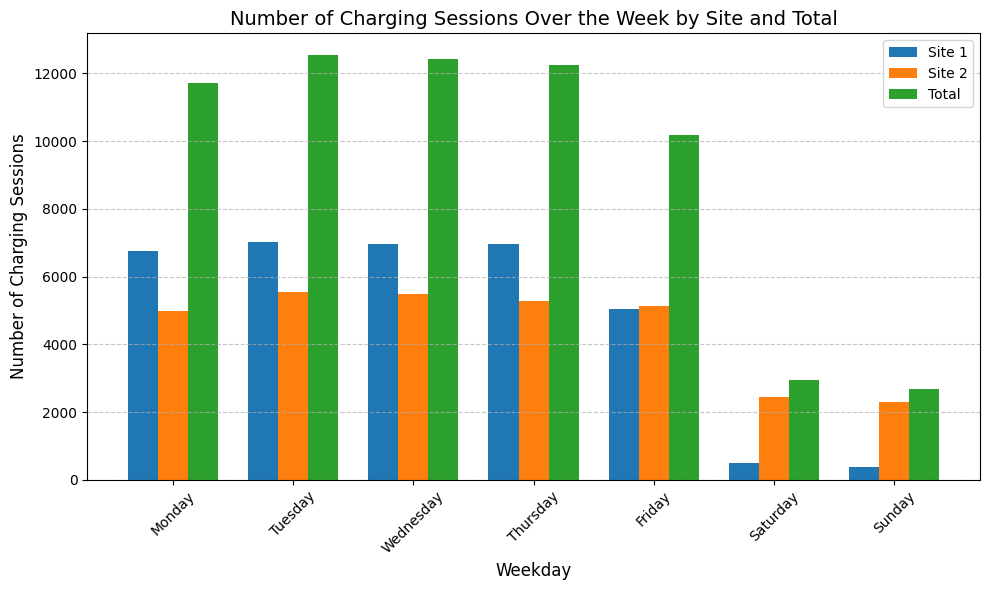

In [8]:

# Wochentag berechnen
data_charge["weekday"] = data_charge["connectionTime"].dt.dayofweek

# Wertanzahl der Wochentage pro Site berechnen
charging_by_weekday_site1 = data_charge[data_charge["siteID"] == 1]["weekday"].value_counts().sort_index()
charging_by_weekday_site2 = data_charge[data_charge["siteID"] == 2]["weekday"].value_counts().sort_index()
charging_by_weekday_total = data_charge["weekday"].value_counts().sort_index()

# Labels für die Wochentage
weekday_labels = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_indices = list(range(7))

# Plot erstellen
plt.figure(figsize=(10, 6))
bar_width = 0.25  # Breite der Balken

# Balken für Site 1 (links)
plt.bar([i - bar_width for i in weekday_indices], charging_by_weekday_site1, width=bar_width, label="Site 1")

# Balken für Site 2 (zentral)
plt.bar(weekday_indices, charging_by_weekday_site2, width=bar_width, label="Site 2")

# Balken für Gesamtzahl (rechts)
plt.bar([i + bar_width for i in weekday_indices], charging_by_weekday_total, width=bar_width, label="Total")

# Titel und Achsenbeschriftungen
plt.title("Number of Charging Sessions Over the Week by Site and Total", fontsize=14)
plt.xlabel("Weekday", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(weekday_indices, weekday_labels, rotation=45)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


#### Seasonal Patterns

Hint: Normalisierung noch sinnvoll (es gibt mehr Sommer als Wintermonate im Datensatz)

c:\Users\janos\anaconda3\envs\JHNLPmitNLTK\lib\site-packages\pandas\core\arrays\datetimes.py:1092: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  UserWarning,


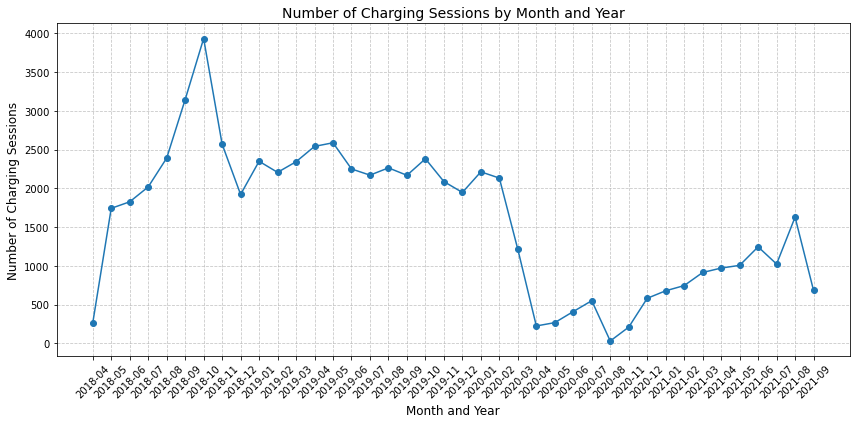

In [10]:
data_charge["month_year"] = data_charge["connectionTime"].dt.to_period("M")
charging_by_month_year = data_charge["month_year"].value_counts().sort_index()

# plot
plt.figure(figsize=(12, 6))
plt.plot(charging_by_month_year.index.astype(str), charging_by_month_year.values, marker="o")
plt.title("Number of Charging Sessions by Month and Year", fontsize=14)
plt.xlabel("Month and Year", fontsize=12)
plt.ylabel("Number of Charging Sessions", fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

We can see that the start of the charging session recording is in April 2018 and ends in September 2021, which is why not every month occurs equally often and we therefore have to normalise. We also see a gap between 08/2020 and 11/2020.

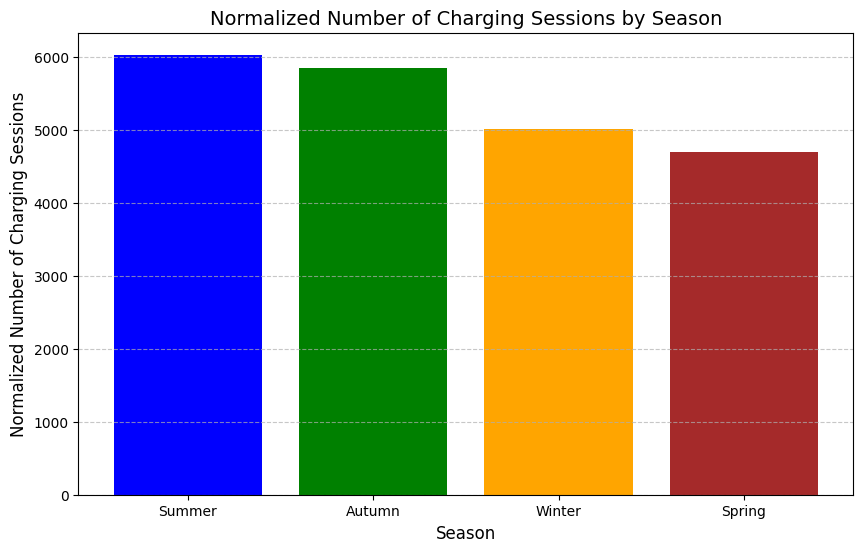

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Funktion zur Bestimmung der Saison
def get_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"

data_charge["season"] = data_charge["connectionTime"].apply(get_season)

charging_by_season = data_charge["season"].value_counts()


season_month_count = {
    "Winter": len(data_charge[data_charge["season"] == "Winter"]["connectionTime"].dt.month.unique()),
    "Spring": len(data_charge[data_charge["season"] == "Spring"]["connectionTime"].dt.month.unique()),
    "Summer": len(data_charge[data_charge["season"] == "Summer"]["connectionTime"].dt.month.unique()),
    "Autumn": len(data_charge[data_charge["season"] == "Autumn"]["connectionTime"].dt.month.unique())
}

normalized_charging_by_season = charging_by_season / [season_month_count[season] for season in charging_by_season.index]

# Plot
plt.figure(figsize=(10, 6))
plt.bar(
    normalized_charging_by_season.index,
    normalized_charging_by_season.values,
    color=["blue", "green", "orange", "brown"]
)
plt.title("Normalized Number of Charging Sessions by Season", fontsize=14)
plt.xlabel("Season", fontsize=12)
plt.ylabel("Normalized Number of Charging Sessions", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


C:\Users\Reintjes\AppData\Local\Temp\ipykernel_13996\2870016461.py:35: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2893.6666666666665' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  normalized_charging_by_season_site.loc[season] = charging_by_season_site.loc[season] / season_month_count[season]
C:\Users\Reintjes\AppData\Local\Temp\ipykernel_13996\2870016461.py:35: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '2957.6666666666665' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  normalized_charging_by_season_site.loc[season] = charging_by_season_site.loc[season] / season_month_count[season]


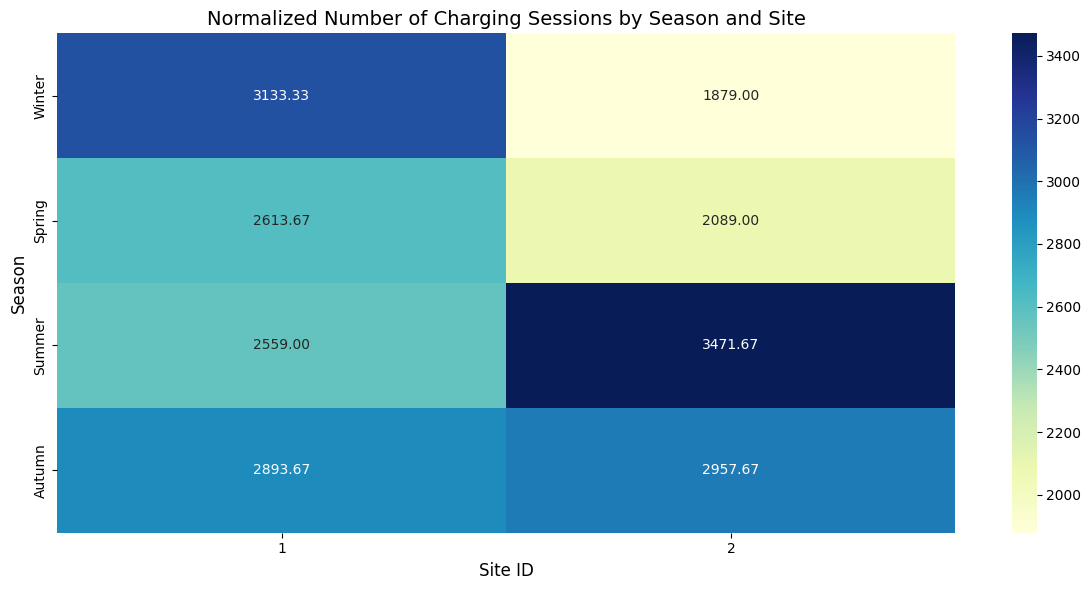

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Funktion zur Bestimmung der Saison
def get_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    elif month in [9, 10, 11]:
        return "Autumn"

# Saison-Spalte erstellen
data_charge["season"] = data_charge["connectionTime"].apply(get_season)

# Berechnen der Monate, die für jede Saison im Datensatz vorhanden sind
season_month_count = {
    "Winter": len(data_charge[data_charge["season"] == "Winter"]["connectionTime"].dt.month.unique()),
    "Spring": len(data_charge[data_charge["season"] == "Spring"]["connectionTime"].dt.month.unique()),
    "Summer": len(data_charge[data_charge["season"] == "Summer"]["connectionTime"].dt.month.unique()),
    "Autumn": len(data_charge[data_charge["season"] == "Autumn"]["connectionTime"].dt.month.unique())
}

# Gruppieren nach Saison und Site
charging_by_season_site = data_charge.groupby(["season", "siteID"]).size().unstack(fill_value=0)

# Normalisierung der Anzahl der Ladesitzungen, indem durch die tatsächliche Anzahl der Monate in jeder Saison geteilt wird
normalized_charging_by_season_site = charging_by_season_site.copy()

for season in charging_by_season_site.index:
    normalized_charging_by_season_site.loc[season] = charging_by_season_site.loc[season] / season_month_count[season]

# Reihenfolge der Saisonen nach "Winter", "Spring", "Summer", "Autumn" sortieren
season_order = ["Winter", "Spring", "Summer", "Autumn"]
normalized_charging_by_season_site = normalized_charging_by_season_site.reindex(season_order)

# Plot
plt.figure(figsize=(12, 6))

# Erstellen der Heatmap für alle Sites und Saisonen
sns.heatmap(normalized_charging_by_season_site, cmap="YlGnBu", annot=True, fmt=".2f", cbar=True)

plt.title("Normalized Number of Charging Sessions by Season and Site", fontsize=14)
plt.xlabel("Site ID", fontsize=12)
plt.ylabel("Season", fontsize=12)
plt.tight_layout()
plt.show()


## KPI
Key Performance Indicators (KPIs): Define three time-dependent KPIs that you would include in a dashboard for the hub operator. These KPIs must provide an immediate overview of the current hub operation and how it is doing in terms of utilization or other business-related aspects. Briefly explain the rationale behind selecting each KPI, explain why you have chosen it and, where needed, provide references. Calculate hourly values for the selected KPIs and visualize them over time. Which trends do you observe? How do you explain them?

1. kWh Delivered (Proxy for revenue and safed CO2-emissions) (Sum(kWh))
2. Utilization rate per hour (The utilization rate indicates how often charging stations are in use compared to how often they are available) (vielleicht auch Abweichung von Stunde,Wochentag,Season) -> zu viel/wenig charging stations
3. Charge time ratio (chargetime/connection time) -> Accessabilty and efficient use of the stations -> maybe increase charging stations or punish blocking time by still a bit charging money while blocking


Source: @article{article,
author = {Helmus, Jurjen and van den Hoed, Robert},
year = {2016},
month = {12},
pages = {733-741},
title = {Key Performance Indicators of Charging infrastructure},
volume = {8},
journal = {World Electric Vehicle Journal},
doi = {10.3390/wevj8040733}
}

## Indentify site
Site Characteristics: The hub operator provided you with the data set, but has seemed to forget which site was supplying which data... Can you find out which of the two sites is the public one?
Try to combine data understanding from previous descriptive analytics with domain knowledge (business understanding) of how private vs. public charging hubs might differ in operation. Explain your line of thought!

From the previous temporal patterns and seasonality analysis following description can be made:
- the charging usage during the day differ a lot: At Site 1 most of the EVs are connected around 6/7 am, while at Site 2 most connections start at 8/9 am. However, at Site 2 the peak of connection hour is not that high as at Site 1, the connection time is way more distributed over the day. Furthermore, usage of the charging station over the night is more likely at Site 2.
- During the week the number of charging stessions by site differ as well: While Site 1 is most of the time used during the week and almost not used during the weekend, Site 2 shows usage over the whole week. The usage during the weekend is lower, too, but not such a high difference as at Site 1.
- Similar to the usage during the day and week, the usage by season shows differences as well: Site 1 is used over the whole year somehow equally. On the other hand, Site 2 shows a more unfairly distribution: It is most of the time used in the summer, then autumn, then spring and then winter.

Site 1: private
Site 2: public